<h1>Ordered Theorell-Chance Model for two Substrates</h1>
<h3>Comparison of alternative models</h3>
<h3>Model as opposed to the "Random Sequential model"</h3>
<p>G. Woehlke 2015 ff (converted from Wolfram Mathematica, aided by A.I.)</p>
<p>This version calculates the time trace (not the equilibrium state)</p>

<h3>Kinetic scheme: </h3> 
<p>Several oxidoreducases oxidize alcohol to aldehyde, and confer the reducing equivalents to NAD+. Upon binding the alcohol, the enzyme is able to accept NAD+, and release the products quickly without detectable trinary intermediate EAB. 
However, an alternative may be the random sequential binding of either substrate. This random sequential reaction scheme may be analyzed by: </p>
<img src="2-09_OrderedADH.png" width="466">  
<p>This gives the following set of equations:</p><ol>
<li>$d{c}_{E}/dt = -k_{12} c_{A}(t) c_{E}(t) + k_{21} c_{EA}(t)+k_{34} c_{EB}(t)$</li>
<li>$d{c}_{EA}/dt = k_{12} c_{A}(t) c_{E}(t)- k_{23} c_{EA}(t)-k_{21} c_{EA}(t)+k_{32} c_{EB}(t)$</li>
<li>$d{c}_{EB}/dt = -k_{34} c_{EB}(t)+k_{23} c_{EA}(t) - k_{31} c_{EB}(t)$</li>
<li>$E_{total}=c_{E}(t)+c_{EA}(t)+c_{EB}(t)$ </li>
</ol>

<p>Assume (from the corresponding Mathematica notebook): </p>
<p><font face="Courier">rates = {k12 = 0.25, k21 = 0.1, k23 = 0.2, k32 = 0.5, k34 = 1.}</font>,</p>
<p><font face="Courier">init = <|cE -> 50, cA -> 250, cB -> 100, cEA -> 0, cEB -> 0, cPA -> 0,
   cPB -> 0|></font>.</p>

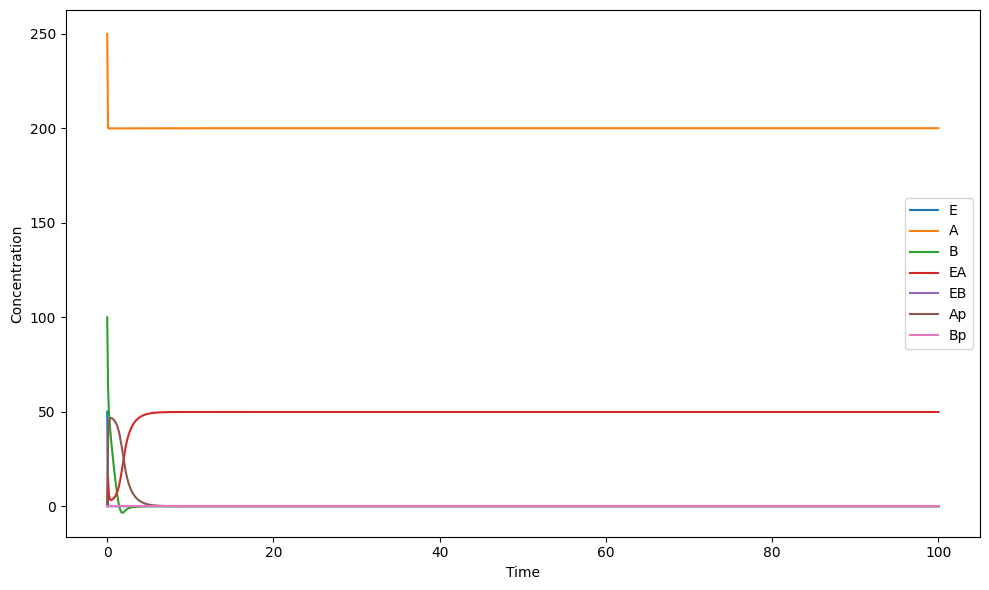

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ---------------------------
# Parameters
# ---------------------------

k12 = 0.25
k21 = 0.10
k23 = 0.20
k32 = 0.50
k34 = 1.00

# ---------------------------
# Initial conditions
# ---------------------------

E0   = 50
A0   = 250
B0   = 100
EA0  = 0
EB0  = 0
Ap0  = 0
Bp0  = 0

y0 = [E0, A0, B0, EA0, EB0, Ap0, Bp0]

# ---------------------------
# Time interval
# ---------------------------

t_end = 100.0

# ---------------------------
# ODE system
# ---------------------------

def reaction_system(t, y):
    E, A, B, EA, EB, Ap, Bp = y

    # Reaction rates
    r12 = k12 * E * A
    r21 = k21 * EA

    r23 = k23 * EA * B
    r32 = k32 * Ap

    r34 = k34 * EB 

    # Differential equations
    dE   = -r12 + r21 + r34
    dA   = -r12 + r21 
    dB   = -r23 - r32 

    dEA  = +r12 - r21 - r23 + r32
    dEB  = +r32 - r32 - r34 

    dAp  =  r23 - r32
    dBp  =  r34 

    return [dE, dA, dB, dEA, dEB, dAp, dBp]

# ---------------------------
# Numerical solution
# ---------------------------

t_eval = np.linspace(0, t_end, 1000)

sol = solve_ivp(
    reaction_system,
    (0, t_end),
    y0,
    t_eval=t_eval,
    method="LSODA"   # good choice for biochemical kinetics
)

# ---------------------------
# Plot
# ---------------------------

labels = ["E", "A", "B", "EA", "EB", "Ap", "Bp"]

plt.figure(figsize=(10, 6))

for i, label in enumerate(labels):
    plt.plot(sol.t, sol.y[i], label=label)

plt.xlabel("Time")
plt.ylabel("Concentration")
plt.legend()
plt.tight_layout()
plt.show()

<h2>Interactive version:</h2>

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

import ipywidgets as widgets
from ipywidgets import interact

# =====================================================
# Solve the ODE system once
# =====================================================

k12 = 0.25
k21 = 0.10
k23 = 0.20
k32 = 0.50
k34 = 1.00

def reaction_system(t, y):
    E, A, B, EA, EB, Ap, Bp = y

    # Reaction rates
    r12 = k12 * E * A
    r21 = k21 * EA

    r23 = k23 * EA * B
    r32 = k32 * Ap

    r34 = k34 * EB 

    # Differential equations
    dE   = -r12 + r21 + r34
    dA   = -r12 + r21 
    dB   = -r23 + r32 

    dEA  = +r12 - r21 - r23 + r32
    dEB  = +r23 - r32 - r34 

    dAp  =  r23 - r32
    dBp  =  r34 

    return [dE, dA, dB, dEA, dEB, dAp, dBp]


y0 = [50, 250, 100, 0, 0, 0, 0]

t_end = 100.0

t = np.linspace(0.001, t_end, 2000)

sol = solve_ivp(
    reaction_system,
    (0, t_end),
    y0,
    t_eval=t,
    method="LSODA"
)

labels = ["cE", "cA", "cB", "cEA", "cEB", "cAp", "cBp"]

# =====================================================
# Interactive plotting function
# =====================================================

def plot_model(
    grid=True,
    font_size=18,
    line_thickness=2.5,
    image_width=900,
    tE=t_end
):

    fig_height = image_width / 150
    fig_width  = image_width / 100

    plt.figure(figsize=(fig_width, fig_height))

    mask = sol.t <= tE

    for i, label in enumerate(labels):
        plt.semilogx(
            sol.t[mask],
            sol.y[i][mask],
            linewidth=line_thickness,
            label=label
        )

    plt.xlabel("log(time)", fontsize=font_size)
    plt.ylabel("concentrations", fontsize=font_size)

    plt.title(
        "ADH (Random Sequential Model)",
        fontsize=font_size + 2
    )

    plt.legend(fontsize=max(8, font_size-4))

    plt.tick_params(
        axis='both',
        labelsize=font_size-2
    )

    plt.grid(grid)

    plt.tight_layout()
    plt.show()

# =====================================================
# Interactive controls (Mathematica Manipulate analogue)
# =====================================================

interact(
    plot_model,

    grid=widgets.Dropdown(
        options=[("None", False),
                 ("Automatic", True)],
        value=True,
        description="Grid"
    ),

    font_size=widgets.Dropdown(
        options=[12,14,18,24,28,36],
        value=18,
        description="Font"
    ),

    line_thickness=widgets.Dropdown(
        options=[1.5,2.5,4,5,7],
        value=2.5,
        description="Width"
    ),

    image_width=widgets.Dropdown(
        options=[450,650,720,900,1200,1920],
        value=900,
        description="Size"
    ),

    tE=widgets.FloatSlider(
        value=t_end,
        min=0.2,
        max=t_end,
        step=0.2,
        description="x-range",
        continuous_update=False
    )
);

interactive(children=(Dropdown(description='Grid', index=1, options=(('None', False), ('Automatic', True)), va…

<h3>Figure legend:</h3>
<p>The graph shows the calculated time traces of reaction educts, products, and intermediates. </p>